# 04 — LSTM Forecaster

A neural-network model for 1–7-day demand forecasts, evaluated on exactly the same 359 rolling forecasts across 2025 as the baselines (seasonal naive, SARIMA, Prophet).

**Approach**
- **Inputs:** the 28 days before each forecast origin (scaled demand plus calendar features), and the calendar features of the 7 days being forecast. No future demand is ever used as an input.
- **Calendar features** are encoded as sin/cos pairs, so Sunday sits next to Monday and 31 Dec next to 1 Jan. Day-of-year gives the model its position in the yearly cycle, which the EDA showed is 2.9× bigger than the weekly cycle and which a 28-day window can't see on its own.
- **Model:** an LSTM summarises the 28-day history; a linear layer combines that summary with the upcoming calendar and predicts all 7 days at once.
- **Split by target date:** train 2021–2023, validation 2024 (used only to decide when to stop training), test 2025.

**Result:** MAE 1,316 MW on 2025, 12% lower than SARIMA and Prophet, and the best of the four models at every horizon except day 1 (single training run; see section 6).

**Sections:** 1. Scaling · 2. Windows · 3. Leakage checks · 4. Model and training · 5. Test on 2025 · 6. Results

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
sys.path.append("..")
from src.config import *          # shared: paths, TARGET, test year, HORIZON, forecast_origins()
from src.lstm_config import *     # LSTM only: VAL_START, LOOKBACK, model and training settings
from src.lstm_data import *       # calendar encoding, scaler, windows
from src.lstm_model import *      # DemandLSTM, loaders, training loop
from src.evaluation import evaluate_and_save, load_predictions, comparison_table, horizon_table

daily = pd.read_csv(PROCESSED_DATA, index_col="date", parse_dates=True)
frame = add_calendar_encodings(daily)

## 1. Scaling
Demand is scaled to 0–1 with a `MinMaxScaler` fitted on **2021–2023 only**. Fitting it on later years would leak their minimum and maximum into training. 2025 therefore falls slightly outside 0–1 (−0.06 to 1.02), which is why the model's output layer is linear rather than squashed into 0–1.

In [2]:
train_end = VAL_START - pd.Timedelta(days=1)          # 2023-12-31
scaler = fit_scaler(frame, TARGET, fit_end=train_end)
frame["demand_scaled"] = scaler.transform(frame[[TARGET]]).ravel()

print(f"Scaler fitted on {frame.index[0].date()} -> {train_end.date()}: "
      f"min {scaler.data_min_[0]:,.0f} MW, max {scaler.data_max_[0]:,.0f} MW")
for name, (a, b) in {"train": (None, train_end),
                     "val": (VAL_START, TRAIN_END),
                     "test": (TEST_START, TEST_END)}.items():
    s = frame.loc[a:b, "demand_scaled"]
    print(f"  {name:5s} scaled range: {s.min():.3f} to {s.max():.3f}")

Scaler fitted on 2021-01-01 -> 2023-12-31: min 17,715 MW, max 37,587 MW
  train scaled range: 0.000 to 1.000
  val   scaled range: 0.020 to 0.971
  test  scaled range: -0.062 to 1.020


## 2. Build windows
Each example: `X_past` (28 days × 7 features), `X_future` (7 days × 6 calendar features) and `y` (7 days of demand). Examples are assigned to a split by the dates they forecast:

| Split | Forecast origins | Examples | Used for |
|---|---|---|---|
| Train | Jan 2021 – Dec 2023 | 1,061 | Learning the weights |
| Validation | 2024 | 360 | Choosing when to stop training |
| Test | 2025 | 359 | Final score only (same origins as the baselines) |

The LSTM learns from one year less data than SARIMA and Prophet, because 2024 is held back for validation.

In [3]:
first_possible = frame.index[LOOKBACK]                 # first day with 28 days of history
train_origins = origins_between(frame.index, first_possible, train_end, HORIZON)
val_origins = origins_between(frame.index, VAL_START, TRAIN_END, HORIZON)
test_origins = forecast_origins()                      # identical to the baselines

Xp_tr, Xf_tr, y_tr, o_tr = make_windows(frame, train_origins, LOOKBACK, HORIZON)
Xp_va, Xf_va, y_va, o_va = make_windows(frame, val_origins, LOOKBACK, HORIZON)
Xp_te, Xf_te, y_te, o_te = make_windows(frame, test_origins, LOOKBACK, HORIZON)

for name, Xp, Xf, yy, oo in [("train", Xp_tr, Xf_tr, y_tr, o_tr),
                             ("val", Xp_va, Xf_va, y_va, o_va),
                             ("test", Xp_te, Xf_te, y_te, o_te)]:
    print(f"{name:5s}  X_past {Xp.shape}  X_future {Xf.shape}  y {yy.shape}  "
          f"origins {oo[0].date()} -> {oo[-1].date()}")

train  X_past (1061, 28, 7)  X_future (1061, 7, 6)  y (1061, 7)  origins 2021-01-29 -> 2023-12-25
val    X_past (360, 28, 7)  X_future (360, 7, 6)  y (360, 7)  origins 2024-01-01 -> 2024-12-25
test   X_past (359, 28, 7)  X_future (359, 7, 6)  y (359, 7)  origins 2025-01-01 -> 2025-12-25


## 3. Leakage and correctness checks
Confirms that no training target falls in 2024, no validation target falls in 2025, the test origins match the baselines, one test window matches the raw data exactly, and un-scaling recovers the original MW values.

In [4]:
one = pd.Timedelta(days=1)
last_train_target = o_tr[-1] + (HORIZON - 1) * one
last_val_target = o_va[-1] + (HORIZON - 1) * one

assert last_train_target < VAL_START, "a training target falls inside the validation period"
assert last_val_target < TEST_START, "a validation target falls inside the test year"
assert list(o_te) == list(test_origins), "test origins differ from the baselines"
print(f"Last training target day:   {last_train_target.date()}  (validation starts {VAL_START.date()})")
print(f"Last validation target day: {last_val_target.date()}  (test starts {TEST_START.date()})")

# Spot-check one test window against the raw data
o = o_te[0]
pos = frame.index.get_loc(o)
past_dates = frame.index[pos - LOOKBACK : pos]
print(f"\nTest window 0: origin {o.date()}, input days {past_dates[0].date()} -> {past_dates[-1].date()}")
assert np.allclose(Xp_te[0][:, 0], frame.loc[past_dates, "demand_scaled"].to_numpy())
assert np.allclose(scaler.inverse_transform(y_te[0].reshape(-1, 1)).ravel(),
                   frame.loc[o : o + (HORIZON - 1) * one, TARGET].to_numpy(), atol=0.5)
print("Window contents match the raw data; inverse-transform recovers MW values: OK")

Last training target day:   2023-12-31  (validation starts 2024-01-01)
Last validation target day: 2024-12-31  (test starts 2025-01-01)

Test window 0: origin 2025-01-01, input days 2024-12-04 -> 2024-12-31
Window contents match the raw data; inverse-transform recovers MW values: OK


## 4. Model and training

**Architecture:** the LSTM reads the 28-day history and compresses it into a 64-number summary. That summary is joined with the flattened calendar features of the 7 days ahead (42 numbers), and a linear layer outputs all 7 forecasts at once. Predicting all 7 days directly avoids feeding the model's own predictions back in, where a day-1 error would compound by day 7.

**Training:** MSE loss on scaled values, Adam optimiser (learning rate 0.001), batches of 32. Validation loss on 2024 is checked after every epoch. Training stops after 25 epochs without improvement, and the best weights are restored. Training examples are shuffled, which is safe because the split by date happens first. Gradient clipping guards against unstable updates, and a fixed seed makes runs repeatable.

### 4a. Data loaders

In [5]:
set_seed(SEED)
train_loader = make_loader(Xp_tr, Xf_tr, y_tr, BATCH_SIZE, shuffle=True, seed=SEED)
val_loader = make_loader(Xp_va, Xf_va, y_va, BATCH_SIZE, shuffle=False)

mw_per_unit = scaler.data_max_[0] - scaler.data_min_[0]   # converts scaled errors to MW
print(f"{len(train_loader)} training batches, {len(val_loader)} validation batches; "
      f"1 scaled unit = {mw_per_unit:,.0f} MW")

34 training batches, 12 validation batches; 1 scaled unit = 19,872 MW


### 4b. Build the model and check shapes
One batch is passed through the untrained model to confirm the output shape matches the target before any training happens.

In [6]:
model = DemandLSTM(
    n_past_features=Xp_tr.shape[2],
    n_future_features=Xf_tr.shape[2],
    horizon=HORIZON,
    hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT,
)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

# One batch through the untrained model: catches shape bugs now, not halfway through training
x_past, x_future, y_batch = next(iter(train_loader))
with torch.no_grad():
    out = model(x_past, x_future)
print(f"x_past {tuple(x_past.shape)}  x_future {tuple(x_future.shape)}  ->  "
      f"output {tuple(out.shape)}  (target {tuple(y_batch.shape)})")
assert out.shape == y_batch.shape, "model output and target shapes don't match"

DemandLSTM(
  (lstm): LSTM(7, 64, batch_first=True)
  (head): Linear(in_features=106, out_features=7, bias=True)
)
Trainable parameters: 19,437
x_past (32, 28, 7)  x_future (32, 7, 6)  ->  output (32, 7)  (target (32, 7))


### 4c. Train with early stopping
Validation MAE is logged in MW (scaled error × the scaler's range) so it can be read alongside the baselines.

In [7]:
history, best_epoch = train_model(
    model, train_loader, val_loader, mw_per_unit,
    lr=LEARNING_RATE, max_epochs=MAX_EPOCHS, patience=PATIENCE,
)

epoch   1  train loss 0.13961  val loss 0.01516  val MAE 1,904 MW  (best epoch 1)
epoch  10  train loss 0.00824  val loss 0.00867  val MAE 1,497 MW  (best epoch 9)
epoch  20  train loss 0.00740  val loss 0.00716  val MAE 1,330 MW  (best epoch 17)
epoch  30  train loss 0.00626  val loss 0.00654  val MAE 1,270 MW  (best epoch 30)
epoch  40  train loss 0.00558  val loss 0.00608  val MAE 1,227 MW  (best epoch 31)
epoch  50  train loss 0.00539  val loss 0.00747  val MAE 1,322 MW  (best epoch 46)
epoch  60  train loss 0.00532  val loss 0.00669  val MAE 1,250 MW  (best epoch 46)
epoch  70  train loss 0.00504  val loss 0.00653  val MAE 1,230 MW  (best epoch 46)
Early stopping at epoch 71: no improvement for 25 epochs.
Best epoch 46: val loss 0.00593, val MAE 1,204 MW  (5s)


### 4d. Learning curves

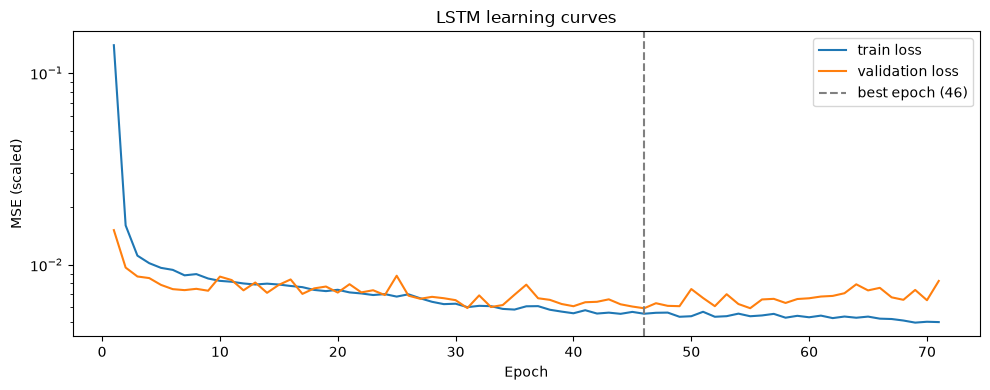

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history["epoch"], history["train_loss"], label="train loss")
ax.plot(history["epoch"], history["val_loss"], label="validation loss")
ax.axvline(best_epoch, color="grey", linestyle="--", label=f"best epoch ({best_epoch})")
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE (scaled)")
ax.set_title("LSTM learning curves")
ax.legend()
plt.tight_layout()
plt.show()

**Training result:** early stopping chose epoch 46 (validation MAE 1,204 MW on 2024) and stopped at epoch 71. Validation loss tracks training loss until about epoch 35, then flattens while training loss keeps falling, which is the onset of overfitting. Early stopping restored the weights from before it. Validation loss is noisy from epoch to epoch, so the exact best epoch is partly down to chance; a learning-rate schedule could smooth this during tuning.

Note: this validation score is optimistic, because 2024 was used to choose the stopping epoch. The unbiased comparison with the baselines is the 2025 test score.

### 4e. Save the best weights
The checkpoint stores the weights, the settings used, and the scaler's min and max, which the dashboard needs to convert predictions back to MW. It's about 80 KB, and `models/` is git-ignored.

In [9]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
ckpt = MODELS_DIR / "lstm_best.pt"
torch.save({
    "state_dict": model.state_dict(),
    "best_epoch": best_epoch,
    "config": {"lookback": LOOKBACK, "hidden_size": HIDDEN_SIZE, "num_layers": NUM_LAYERS,
               "dropout": DROPOUT, "learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE},
    "scaler_min": float(scaler.data_min_[0]),
    "scaler_max": float(scaler.data_max_[0]),
}, ckpt)
print(f"Saved best weights to {ckpt} ({ckpt.stat().st_size / 1024:.0f} KB)")

Saved best weights to /Users/jay/Documents/Project 5/uk-grid-demand-forecasting/models/lstm_best.pt (79 KB)


## 5. Test on 2025

### 5a. Reload the best model from disk
Reloading the saved checkpoint, rather than using the model still in memory, means this section works after a kernel restart and proves the saved file is usable. The checks confirm the checkpoint was trained with the same lookback and scaler.

In [10]:
ckpt = torch.load(MODELS_DIR / "lstm_best.pt", weights_only=False)
cfg = ckpt["config"]
model = DemandLSTM(
    n_past_features=Xp_te.shape[2], n_future_features=Xf_te.shape[2], horizon=HORIZON,
    hidden_size=cfg["hidden_size"], num_layers=cfg["num_layers"], dropout=cfg["dropout"],
)
model.load_state_dict(ckpt["state_dict"])
model.eval()

# The checkpoint must match the data it's about to predict on
assert cfg["lookback"] == LOOKBACK, "checkpoint was trained with a different lookback"
assert np.isclose(ckpt["scaler_min"], scaler.data_min_[0]) and np.isclose(ckpt["scaler_max"], scaler.data_max_[0]), \
    "checkpoint was trained with a different scaler"
print(f"Loaded checkpoint from epoch {ckpt['best_epoch']}; lookback and scaler match: OK")

Loaded checkpoint from epoch 46; lookback and scaler match: OK


### 5b. Predict and convert back to MW
The scaler works on a single column, so the (359, 7) predictions are flattened, converted and reshaped back.

In [11]:
with torch.no_grad():
    pred_scaled = model(torch.from_numpy(Xp_te), torch.from_numpy(Xf_te)).numpy()
print("Scaled predictions:", pred_scaled.shape,
      f"range {pred_scaled.min():.3f} to {pred_scaled.max():.3f}")

# The scaler expects one column, so flatten to (n, 1), convert, then reshape back to (359, 7)
pred_mw = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).reshape(pred_scaled.shape)
print(f"Predictions in MW: {pred_mw.min():,.0f} to {pred_mw.max():,.0f}")
assert not np.isnan(pred_mw).any(), "NaN in predictions"

Scaled predictions: (359, 7) range 0.030 to 0.940
Predictions in MW: 18,318 to 36,403


### 5c. Score with the shared evaluation code
`y_true` comes from the raw data, so it's the exact value the baselines were scored against. MASE uses the same 2021–2024 training series as the baselines, so all four models are on the same scale.

In [12]:
rows = []
for i, origin in enumerate(o_te):
    for h in range(1, HORIZON + 1):
        d = origin + pd.Timedelta(days=h - 1)
        rows.append({"model": "lstm", "origin": origin, "date": d, "horizon": h,
                     "y_true": daily.loc[d, TARGET], "y_pred": float(pred_mw[i, h - 1])})
lstm_preds = pd.DataFrame(rows)

# Check the targets line up: un-scaling the test targets must reproduce the raw demand
assert np.allclose(scaler.inverse_transform(y_te.reshape(-1, 1)).ravel(),
                   lstm_preds["y_true"].to_numpy(), atol=0.5), "targets misaligned"
print("Targets aligned with the raw data: OK\n")

y_train_shared = daily[TARGET][:TRAIN_END]       # 2021-2024: the same MASE scale as the baselines
lstm_scores = evaluate_and_save(lstm_preds, "lstm", y_train_shared)

Targets aligned with the raw data: OK

=== lstm ===
  MAE   1,315.726
  RMSE  1,671.848
  MAPE  5.042
  MASE  0.755

  MAE by horizon (days ahead):
horizon
1    1066.0
2    1182.0
3    1284.0
4    1348.0
5    1382.0
6    1456.0
7    1491.0

  Saved 2513 rows to /Users/jay/Documents/Project 5/uk-grid-demand-forecasting/results/predictions/lstm.csv


### 5d. Comparison with the baselines

In [13]:
all_preds = load_predictions()
print("Rows per model:")
print(all_preds.groupby("model").size().to_string(), "\n")

print("Overall scores:")
display(comparison_table(all_preds, y_train_shared).round(3))

print("MAE by horizon (MW):")
display(horizon_table(all_preds).round(0))

Rows per model:
model
lstm              2513
prophet           2513
sarima            2513
seasonal_naive    2513 

Overall scores:


,MAE,RMSE,MAPE,MASE
lstm,1315.726,1671.848,5.042,0.755
sarima,1493.125,1934.043,5.758,0.856
prophet,1495.998,1874.335,5.767,0.858
seasonal_naive,1821.982,2392.299,6.885,1.045


MAE by horizon (MW):


horizon,1,2,3,4,5,6,7
model,,,,,,,
lstm,1066.0,1182.0,1284.0,1348.0,1382.0,1456.0,1491.0
prophet,1430.0,1456.0,1477.0,1503.0,1520.0,1536.0,1550.0
sarima,973.0,1247.0,1376.0,1541.0,1666.0,1784.0,1865.0
seasonal_naive,1844.0,1852.0,1837.0,1823.0,1812.0,1800.0,1786.0


## 6. Results

| Model | MAE (MW) | RMSE (MW) | MAPE | MASE |
|---|---|---|---|---|
| **LSTM** | **1,316** | **1,672** | **5.04%** | **0.755** |
| SARIMA | 1,493 | 1,934 | 5.76% | 0.856 |
| Prophet | 1,496 | 1,874 | 5.77% | 0.858 |
| Seasonal naive | 1,822 | 2,392 | 6.89% | 1.045 |

**MAE by horizon (MW)**

| Days ahead | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|
| LSTM | 1,066 | **1,182** | **1,284** | **1,348** | **1,382** | **1,456** | **1,491** |
| SARIMA | **973** | 1,247 | 1,376 | 1,541 | 1,666 | 1,784 | 1,865 |
| Prophet | 1,430 | 1,456 | 1,477 | 1,503 | 1,520 | 1,536 | 1,550 |
| Seasonal naive | 1,844 | 1,852 | 1,837 | 1,823 | 1,812 | 1,800 | 1,786 |

**Findings**
- The LSTM is the best model overall: 12% lower MAE than SARIMA and Prophet, and 28% lower than seasonal naive, despite training on one year less data (2021–2023).
- It wins every horizon except day 1, where SARIMA's direct use of the latest observations still gives the lowest error.
- A likely explanation: it combines the baselines' strengths. Like SARIMA it uses recent days directly, like Prophet it knows its position in the yearly cycle (day-of-year features), and it knows which upcoming days are holidays.
- **Leakage checks:** scaler fitted on 2021–2023 only; inputs end the day before each origin; future inputs are calendar-only; stopping epoch chosen on 2024; targets aligned with raw data; test origins identical to the baselines.
- **Caveat:** this is a single training run. Results vary with the random starting weights, so the next step retrains with several seeds to check the gap holds.